# DSP391m - DATA SCIENCE CAPSTONE PROJECT
## PROGRESS REPORT 2: DATA WRANGLING & EXPLORATORY DATA ANALYSIS (EDA)

**Tên nhóm:** [Điền tên nhóm]  
**Đề tài lựa chọn:** [Tên đề tài từ Report 1]
**Ngày nộp:** [Ngày/Tháng/Năm]

## I. THU THẬP DỮ LIỆU (DATA COLLECTION)

### 1.1. Quy trình thu thập thực tế
[Sinh viên mô tả chi tiết cách đã lấy dữ liệu: Viết Script Crawl dữ liệu, gọi API, hay tải tệp CSV từ Kaggle/UCI. Nếu dữ liệu từ hệ thống IoT, hãy mô tả luồng MQTT/Database]

### 1.2. Nạp dữ liệu (Data Ingestion)
*Sử dụng code cell bên dưới để nạp dữ liệu vào DataFrame.*

In [3]:
# Code cell: Import thư viện và load dataset
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
import os
import json

DATA_ROOT = Path("./chokepoint_data/extracted")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".ppm", ".pgm"}

def find_groundtruth_files(root=DATA_ROOT):
    root = Path(root)
    candidates = list(root.rglob("*.csv")) + list(root.rglob("*.txt"))
    return candidates

def try_load_table(path):
    # Try common separators, fallback to python engine auto-detect
    for sep in [",", "\t", ";", "|"]:
        try:
            df = pd.read_csv(path, sep=sep, engine="python", nrows=5)
            # If it's a small table header-like file, return
            if df.shape[1] >= 2:
                return pd.read_csv(path, sep=sep, engine="python")
        except Exception:
            pass
    # Last attempt: read with whitespace separator
    try:
        return pd.read_csv(path, delim_whitespace=True, engine="python")
    except Exception:
        return None

def build_images_dataframe(root=DATA_ROOT):
    rows = []
    for p in sorted(root.rglob("*")):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            try:
                with Image.open(p) as img:
                    w, h = img.size
            except Exception:
                w, h = None, None
            relpath = p.as_posix()
            if p.exists():
                try:
                    relpath = p.resolve().relative_to(Path.cwd().resolve()).as_posix()
                except Exception:
                    relpath = p.as_posix()

            rows.append({
                "path": p,
                "relpath": relpath,
                "filename": p.name,
                "suffix": p.suffix.lower(),
                "size_bytes": p.stat().st_size if p.exists() else None,
                "width": w,
                "height": h,
            })
    return pd.DataFrame(rows)

# Execution: attempt to load any tabular ground-truth, else construct images table
gt_candidates = find_groundtruth_files()
print("Ground-truth candidates found:", [str(p) for p in gt_candidates[:10]])
groundtruth_df = None
for cand in gt_candidates:
    df = try_load_table(cand)
    if df is not None:
        groundtruth_df = df
        print(f"Loaded ground-truth table from: {cand} -> shape {df.shape}")
        break

images_df = build_images_dataframe()
print(f"Images discovered: {len(images_df):,}")
# If groundtruth_df exists, try to align with image paths/filenames
if groundtruth_df is not None:
    display(groundtruth_df.head())
else:
    print("No tabular ground-truth loaded; images_df is available for EDA.")
    display(images_df.head())

Ground-truth candidates found: []
Images discovered: 63,628
No tabular ground-truth loaded; images_df is available for EDA.
Images discovered: 63,628
No tabular ground-truth loaded; images_df is available for EDA.


,path,relpath,filename,suffix,size_bytes,width,height
0,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002439.pgm,.pgm,9229,96,96
1,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002440.pgm,.pgm,9229,96,96
2,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002441.pgm,.pgm,9229,96,96
3,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002442.pgm,.pgm,9229,96,96
4,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002443.pgm,.pgm,9229,96,96


## II. LÀM SẠCH DỮ LIỆU (DATA CLEANING)

### 2.1. Kiểm tra tổng quát
*Sinh viên thực hiện kiểm tra các giá trị thiếu (null), trùng lặp (duplicates) và sai kiểu dữ liệu.*

In [4]:
# Code cell: Kiểm tra dữ liệu (info, describe, isnull().sum())
# Generic cleaning utilities for tabular and image metadata DataFrames

def df_overview(df, name="df"):
    print(f"--- Overview: {name} ---")
    print("Shape:", df.shape)
    print("\nDtypes:\n", df.dtypes)
    print("\nMissing values:\n", df.isnull().sum())
    print("\nDuplicates:", df.duplicated().sum())
    display(df.head())

def drop_duplicate_rows(df, subset=None, keep="first"):
    before = df.shape[0]
    df = df.drop_duplicates(subset=subset, keep=keep)
    after = df.shape[0]
    print(f"Dropped {before-after} duplicate rows")
    return df

def fill_missing_numeric(df, strategy="median", numeric_cols=None):
    if numeric_cols is None:
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    for col in numeric_cols:
        if df[col].isnull().any():
            if strategy == "median":
                df[col].fillna(df[col].median(), inplace=True)
            elif strategy == "mean":
                df[col].fillna(df[col].mean(), inplace=True)
            elif strategy == "zero":
                df[col].fillna(0, inplace=True)
            else:
                df[col].fillna(df[col].median(), inplace=True)
    return df

def detect_outliers_iqr(df, col, k=1.5):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - k * iqr
    high = q3 + k * iqr
    return df[(df[col] < low) | (df[col] > high)]

# Apply cleaning to whichever DataFrame you have
if groundtruth_df is not None:
    df_overview(groundtruth_df, "groundtruth_df")
    # Example actions (uncomment to apply)
    # groundtruth_df = drop_duplicate_rows(groundtruth_df)
    # groundtruth_df = fill_missing_numeric(groundtruth_df, strategy="median")
else:
    df_overview(images_df, "images_df")
    images_df = drop_duplicate_rows(images_df, subset=["relpath"])
    # For images, recompute missing width/height if possible
    for idx, row in images_df[images_df["width"].isnull()].iterrows():
        p = Path(row["path"])
        try:
            with Image.open(p) as im:
                images_df.at[idx, "width"], images_df.at[idx, "height"] = im.size
        except Exception:
            pass
    images_df = fill_missing_numeric(images_df, strategy="median", numeric_cols=["width", "height", "size_bytes"])
    display(images_df.describe(include="all"))

--- Overview: images_df ---
Shape: (63628, 7)

Dtypes:
 path          object
relpath       object
filename      object
suffix        object
size_bytes     int64
width          int64
height         int64
dtype: object

Missing values:
 path          0
relpath       0
filename      0
suffix        0
size_bytes    0
width         0
height        0
dtype: int64

Duplicates: 0


,path,relpath,filename,suffix,size_bytes,width,height
0,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002439.pgm,.pgm,9229,96,96
1,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002440.pgm,.pgm,9229,96,96
2,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002441.pgm,.pgm,9229,96,96
3,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002442.pgm,.pgm,9229,96,96
4,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002443.pgm,.pgm,9229,96,96


Dropped 0 duplicate rows


,path,relpath,filename,suffix,size_bytes,width,height
count,63628,63628,63628,63628,6.362800e+04,63628.000000,63628.000000
unique,63628,63628,5480,2,NaN,NaN,NaN
top,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00000532.pgm,.pgm,NaN,NaN,NaN
freq,1,1,35,63570,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,1.388301e+04,99.558685,98.348149
std,NaN,NaN,NaN,NaN,1.545056e+05,117.816211,77.739385
min,NaN,NaN,NaN,NaN,9.229000e+03,96.000000,96.000000
25%,NaN,NaN,NaN,NaN,9.229000e+03,96.000000,96.000000
50%,NaN,NaN,NaN,NaN,9.229000e+03,96.000000,96.000000
75%,NaN,NaN,NaN,NaN,9.229000e+03,96.000000,96.000000


### 2.2. Xử lý dữ liệu lỗi (Data Handling)
[Giải thích lý do lựa chọn phương pháp xử lý: Tại sao bạn xóa cột? Tại sao bạn điền giá trị trung bình vào ô trống?]
- **Xử lý Missing Values:** [Phương pháp]
- **Xử lý Duplicates:** [Phương pháp]
- **Xử lý Outliers:** [Phương pháp]

In [5]:
# Code cell: Thực thi các lệnh làm sạch dữ liệu
# Generic cleaning utilities for tabular and image metadata DataFrames

def df_overview(df, name="df"):
    print(f"--- Overview: {name} ---")
    print("Shape:", df.shape)
    print("\nDtypes:\n", df.dtypes)
    print("\nMissing values:\n", df.isnull().sum())
    print("\nDuplicates:", df.duplicated().sum())
    display(df.head())

def drop_duplicate_rows(df, subset=None, keep="first"):
    before = df.shape[0]
    df = df.drop_duplicates(subset=subset, keep=keep)
    after = df.shape[0]
    print(f"Dropped {before-after} duplicate rows")
    return df

def fill_missing_numeric(df, strategy="median", numeric_cols=None):
    if numeric_cols is None:
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    for col in numeric_cols:
        if df[col].isnull().any():
            if strategy == "median":
                df[col].fillna(df[col].median(), inplace=True)
            elif strategy == "mean":
                df[col].fillna(df[col].mean(), inplace=True)
            elif strategy == "zero":
                df[col].fillna(0, inplace=True)
            else:
                df[col].fillna(df[col].median(), inplace=True)
    return df

def detect_outliers_iqr(df, col, k=1.5):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - k * iqr
    high = q3 + k * iqr
    return df[(df[col] < low) | (df[col] > high)]

# Apply cleaning to whichever DataFrame you have
if groundtruth_df is not None:
    df_overview(groundtruth_df, "groundtruth_df")
    # Example actions (uncomment to apply)
    # groundtruth_df = drop_duplicate_rows(groundtruth_df)
    # groundtruth_df = fill_missing_numeric(groundtruth_df, strategy="median")
else:
    df_overview(images_df, "images_df")
    images_df = drop_duplicate_rows(images_df, subset=["relpath"])
    # For images, recompute missing width/height if possible
    for idx, row in images_df[images_df["width"].isnull()].iterrows():
        p = Path(row["path"])
        try:
            with Image.open(p) as im:
                images_df.at[idx, "width"], images_df.at[idx, "height"] = im.size
        except Exception:
            pass
    images_df = fill_missing_numeric(images_df, strategy="median", numeric_cols=["width", "height", "size_bytes"])
    display(images_df.describe(include="all"))

--- Overview: images_df ---
Shape: (63628, 7)

Dtypes:
 path          object
relpath       object
filename      object
suffix        object
size_bytes     int64
width          int64
height         int64
dtype: object

Missing values:
 path          0
relpath       0
filename      0
suffix        0
size_bytes    0
width         0
height        0
dtype: int64

Duplicates: 0


,path,relpath,filename,suffix,size_bytes,width,height
0,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002439.pgm,.pgm,9229,96,96
1,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002440.pgm,.pgm,9229,96,96
2,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002441.pgm,.pgm,9229,96,96
3,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002442.pgm,.pgm,9229,96,96
4,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002443.pgm,.pgm,9229,96,96


Dropped 0 duplicate rows


,path,relpath,filename,suffix,size_bytes,width,height
count,63628,63628,63628,63628,6.362800e+04,63628.000000,63628.000000
unique,63628,63628,5480,2,NaN,NaN,NaN
top,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00000532.pgm,.pgm,NaN,NaN,NaN
freq,1,1,35,63570,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,1.388301e+04,99.558685,98.348149
std,NaN,NaN,NaN,NaN,1.545056e+05,117.816211,77.739385
min,NaN,NaN,NaN,NaN,9.229000e+03,96.000000,96.000000
25%,NaN,NaN,NaN,NaN,9.229000e+03,96.000000,96.000000
50%,NaN,NaN,NaN,NaN,9.229000e+03,96.000000,96.000000
75%,NaN,NaN,NaN,NaN,9.229000e+03,96.000000,96.000000


## III. KHÁM PHÁ DỮ LIỆU (EDA)

### 3.1. Phân tích đơn biến (Univariate Analysis)
*Vẽ biểu đồ phân phối cho các biến quan trọng.*

Running image metadata EDA
--- Overview: images_df ---
Shape: (63628, 7)

Dtypes:
 path          object
relpath       object
filename      object
suffix        object
size_bytes     int64
width          int64
height         int64
dtype: object

Missing values:
 path          0
relpath       0
filename      0
suffix        0
size_bytes    0
width         0
height        0
dtype: int64

Duplicates: 0


,path,relpath,filename,suffix,size_bytes,width,height
0,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002439.pgm,.pgm,9229,96,96
1,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002440.pgm,.pgm,9229,96,96
2,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002441.pgm,.pgm,9229,96,96
3,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002442.pgm,.pgm,9229,96,96
4,chokepoint_data\extracted\P1E\P1E_S1_C1\0001\0...,chokepoint_data/extracted/P1E/P1E_S1_C1/0001/0...,00002443.pgm,.pgm,9229,96,96


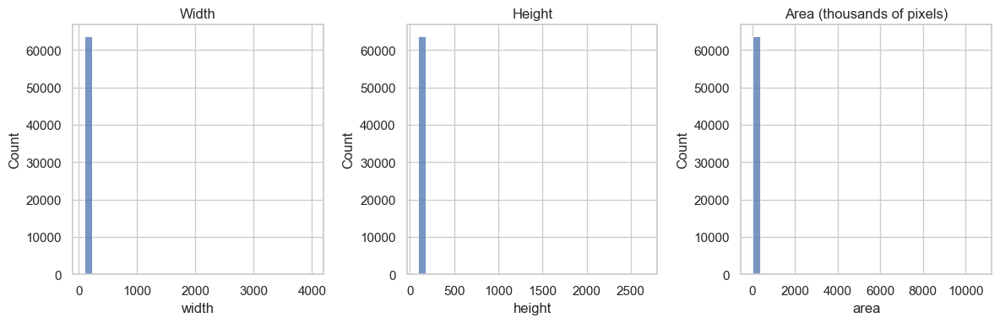

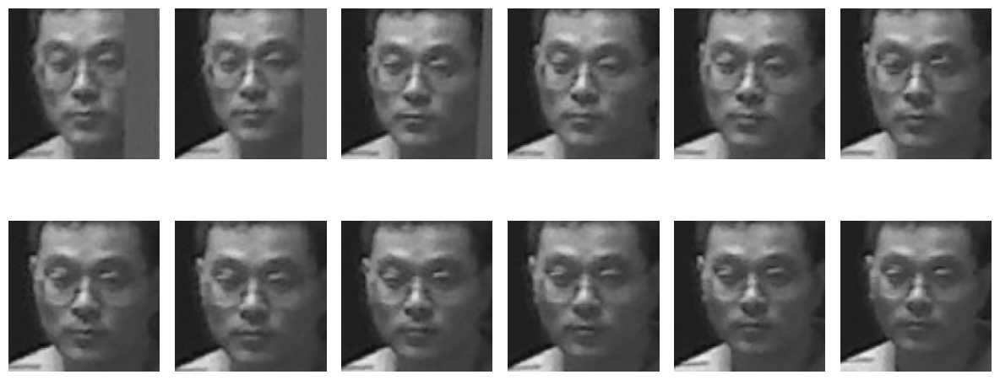

In [6]:
# Code cell: Biểu đồ Histogram, Boxplot, Countplot
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

def univariate_numeric_plots(df, cols=None, nrows=2, figsize=(12,6)):
    if cols is None:
        cols = df.select_dtypes(include=[np.number]).columns.tolist()
    for col in cols:
        plt.figure(figsize=figsize)
        plt.suptitle(f"Distribution and boxplot: {col}")
        plt.subplot(1,2,1)
        sns.histplot(df[col].dropna(), kde=True, bins=40)
        plt.subplot(1,2,2)
        sns.boxplot(x=df[col].dropna())
        plt.show()

def univariate_categorical_counts(df, cols=None, top_n=20, figsize=(8,4)):
    if cols is None:
        cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
    for col in cols:
        counts = df[col].value_counts().nlargest(top_n)
        plt.figure(figsize=figsize)
        sns.barplot(x=counts.values, y=counts.index, palette="muted")
        plt.title(f"Top {top_n} counts for {col}")
        plt.show()

def numeric_correlation_heatmap(df, cols=None, figsize=(10,8)):
    if cols is None:
        cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if len(cols) < 2:
        print("Not enough numeric columns for correlation.")
        return
    corr = df[cols].corr()
    plt.figure(figsize=figsize)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
    plt.title("Numeric feature correlation")
    plt.show()

# Image-specific EDA
def image_size_distribution(img_df):
    if img_df is None or img_df.empty:
        print("No image metadata available")
        return
    img_df = img_df.copy()
    img_df["area"] = img_df["width"] * img_df["height"]
    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1)
    sns.histplot(img_df["width"].dropna(), bins=30)
    plt.title("Width")
    plt.subplot(1,3,2)
    sns.histplot(img_df["height"].dropna(), bins=30)
    plt.title("Height")
    plt.subplot(1,3,3)
    sns.histplot(img_df["area"].dropna()/1e3, bins=30)
    plt.title("Area (thousands of pixels)")
    plt.tight_layout()
    plt.show()

def sample_images_grid(paths, n=12, cols=6, figsize=(12,6)):
    from PIL import Image
    import math
    n = min(n, len(paths))
    rows = math.ceil(n/cols)
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten()
    for ax in axes:
        ax.axis("off")
    for ax, p in zip(axes, paths[:n]):
        try:
            with Image.open(p) as im:
                ax.imshow(im.convert("RGB"))
        except Exception:
            ax.text(0.5,0.5,str(p.name), ha="center", va="center")
    plt.tight_layout()
    plt.show()

# Run EDA depending on available data
if groundtruth_df is not None:
    print("Running tabular EDA on groundtruth table")
    df_overview(groundtruth_df, "groundtruth_df")
    # Try to guess a label column
    label_cols = [c for c in groundtruth_df.columns if "label" in c.lower() or "class" in c.lower() or "id" in c.lower()]
    if label_cols:
        print("Candidate label columns:", label_cols)
        univariate_categorical_counts(groundtruth_df, cols=[label_cols[0]])
    numeric_correlation_heatmap(groundtruth_df)
else:
    print("Running image metadata EDA")
    df_overview(images_df, "images_df")
    image_size_distribution(images_df)
    sample_images_grid(images_df["path"].tolist(), n=12)

# Additional: pairplot for a small random sample of numeric features (warning: can be slow)
def small_pairplot(df, numeric_cols=None, sample_n=300):
    if numeric_cols is None:
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if len(numeric_cols) < 2:
        print("Not enough numeric columns for pairplot.")
        return
    s = df[numeric_cols].dropna().sample(min(sample_n, len(df)))
    sns.pairplot(s, corner=True, diag_kind="kde")
    plt.show()

# Example quick call (uncomment to run on current DataFrame)
# if groundtruth_df is not None:
#     small_pairplot(groundtruth_df)
# else:
#     small_pairplot(images_df, numeric_cols=["width","height","size_bytes"])

In [3]:
# Advanced EDA for face data (if available)
import re
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from io import BytesIO
sns.set(style="whitegrid")

# Utilities to parse bboxes from common groundtruth formats
def extract_bboxes_from_table(df):
    # Attempt to detect common bbox column sets
    cols = [c.lower() for c in df.columns]
    # variants: xmin,ymin,xmax,ymax  OR x1,y1,w,h  OR left,top,width,height
    mapping = {}
    for variant in (("xmin","ymin","xmax","ymax"),
                    ("x1","y1","x2","y2"),
                    ("left","top","right","bottom"),
                    ("left","top","width","height"),
                    ("x","y","w","h")):
        if all(any(variant[i] == c for c in cols) for i in range(len(variant))):
            # find actual column names
            for i,name in enumerate(variant):
                for c in df.columns:
                    if c.lower() == name:
                        mapping[name] = c
            break
    if mapping:
        # normalize to xmin,ymin,xmax,ymax
        out = []
        if "width" in mapping or "w" in mapping or "x" in mapping and "y" in mapping and ("w" in mapping or "width" in mapping):
            # left,top,width,height case
            left = mapping.get("left") or mapping.get("x")
            top = mapping.get("top") or mapping.get("y")
            width_col = mapping.get("width") or mapping.get("w")
            height_col = mapping.get("height") or mapping.get("h")
            df2 = df.copy()
            df2["xmin"] = df2[left]
            df2["ymin"] = df2[top]
            df2["xmax"] = df2[left] + df2[width_col]
            df2["ymax"] = df2[top] + df2[height_col]
            out_df = df2.assign(xmin=df2["xmin"], ymin=df2["ymin"], xmax=df2["xmax"], ymax=df2["ymax"])
            return out_df[["xmin","ymin","xmax","ymax"]]
        else:
            # direct map xmin,ymin,xmax,ymax
            cols_map = {k: mapping[k] for k in ("xmin","ymin","xmax","ymax") if k in mapping}
            out_df = df.rename(columns={v:k for k,v in cols_map.items()})
            return out_df[["xmin","ymin","xmax","ymax"]]
    # fallback: look for a single bbox column containing 'x1,y1,x2,y2' strings
    for c in df.columns:
        if df[c].dtype == object and df[c].str.contains(",").any():
            # try parse "x1 y1 x2 y2" or "x y w h"
            parsed = df[c].str.replace(",", " ").str.split().apply(lambda parts: [float(p) for p in parts] if parts is not None and len(parts) in (4,) else None)
            if parsed.dropna().shape[0] > 0:
                rows = []
                for val in parsed:
                    if val is None:
                        rows.append((np.nan, np.nan, np.nan, np.nan))
                    else:
                        x1,y1,x2,y2 = val
                        # heuristic: if values look like x,y,w,h then convert
                        if x2 <= 1 and y2 <= 1:
                            rows.append((np.nan,np.nan,np.nan,np.nan))
                        else:
                            # if x2 < x1 maybe it's x,y,w,h
                            if x2 < x1:
                                rows.append((x1, y1, x1+x2, y1+y2))
                            else:
                                rows.append((x1,y1,x2,y2))
                return pd.DataFrame(rows, columns=["xmin","ymin","xmax","ymax"])
    return None

# Try to read sidecar annotation files (simple txt: xmin ymin xmax ymax per line or x y w h)
def parse_sidecar_annotations(root):
    rows = []
    for p in Path(root).rglob("*.txt"):
        # skip README and non-annotation small files heuristically
        if p.name.lower().startswith("readme") or p.stat().st_size < 10:
            continue
        img_base = p.with_suffix("")  # try to match image names
        with p.open("r", encoding="utf-8", errors="ignore") as f:
            for line in f:
                parts = re.split(r"[,\s]+", line.strip())
                if len(parts) >= 4:
                    try:
                        nums = [float(x) for x in parts[:4]]
                    except Exception:
                        continue
                    # determine format: x,y,w,h if third less than 1000 and likely smaller than image dims
                    x1,y1,x2,y2 = nums
                    if x2 < 1e4 and x2 > x1 and y2 > y1:
                        xmin,ymin,xmax,ymax = x1,y1,x2,y2
                    else:
                        xmin,ymin,xmax,ymax = x1,y1,x1+x2,y1+y2
                    rows.append({"annot_file": str(p), "xmin": xmin, "ymin": ymin, "xmax": xmax, "ymax": ymax})
    return pd.DataFrame(rows) if rows else None

# Build faces_df by merging available sources
def build_faces_df(images_df, groundtruth_df=None, extract_root=Path("./chokepoint_data/extracted")):
    faces = []
    # first try groundtruth table detection
    if groundtruth_df is not None:
        bb = extract_bboxes_from_table(groundtruth_df)
        if bb is not None:
            bb = bb.reset_index(drop=True)
            # attach image paths where possible by filename match
            if 'filename' in groundtruth_df.columns:
                filenames = groundtruth_df['filename'].astype(str)
                for idx,row in bb.iterrows():
                    fn = groundtruth_df.loc[idx,'filename']
                    # find matching image path
                    match = images_df[images_df['filename']==fn]
                    imgp = match['path'].iat[0] if not match.empty else None
                    faces.append({"image_path": imgp, "xmin": row.xmin, "ymin": row.ymin, "xmax": row.xmax, "ymax": row.ymax})
    # fallback: parse sidecar annotation files
    if not faces:
        ann = parse_sidecar_annotations(extract_root)
        if ann is not None:
            for _,r in ann.iterrows():
                faces.append({"image_path": None, "xmin": r.xmin, "ymin": r.ymin, "xmax": r.xmax, "ymax": r.ymax, "annot_file": r.annot_file})
    faces_df = pd.DataFrame(faces)
    # If image_path missing, try to infer from naming in annot_file or images_df
    if 'image_path' in faces_df.columns and faces_df['image_path'].isnull().any():
        # attempt to map by base names
        for i,row in faces_df[faces_df['image_path'].isnull()].iterrows():
            if 'annot_file' in row and row['annot_file']:
                base = Path(row['annot_file']).stem
                cand = images_df[images_df['filename'].str.contains(base)]
                if not cand.empty:
                    faces_df.at[i,'image_path'] = cand['path'].iat[0]
    # compute derived metrics
    if not faces_df.empty:
        faces_df['xmin'] = faces_df['xmin'].astype(float)
        faces_df['ymin'] = faces_df['ymin'].astype(float)
        faces_df['xmax'] = faces_df['xmax'].astype(float)
        faces_df['ymax'] = faces_df['ymax'].astype(float)
        faces_df['width'] = (faces_df['xmax'] - faces_df['xmin']).clip(lower=0)
        faces_df['height'] = (faces_df['ymax'] - faces_df['ymin']).clip(lower=0)
        faces_df['area'] = faces_df['width'] * faces_df['height']
        faces_df['size_px'] = faces_df[['width','height']].min(axis=1)  # use min side as proxy
    return faces_df

# Scale analysis, WIDER-like buckets and cumulative face ratio
def scale_analysis(faces_df, thresholds = {"small": (10,50), "medium": (50,300), "large": (300, 10_000)}):
    if faces_df is None or faces_df.empty:
        print("No face bboxes found for scale analysis.")
        return
    s = faces_df['size_px'].dropna()
    # histogram and cumulative plot
    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    sns.histplot(s, bins=60)
    plt.xlabel("Face size (px, min side)")
    plt.title("Face size distribution")
    plt.subplot(1,2,2)
    vals, edges = np.histogram(s, bins=200)
    cs = np.cumsum(vals)/vals.sum()
    plt.plot(edges[1:], cs)
    plt.xlabel("Face size (px)")
    plt.ylabel("Cumulative ratio")
    for t in [16,32,64,128]:
        plt.axvline(t, color='gray', linestyle='--', alpha=0.6)
        plt.text(t, 0.05, f"{int((s<=t).mean()*100)}%", rotation=90)
    plt.title("Cumulative Face Ratio")
    plt.tight_layout()
    plt.show()

    # bucket stats
    buckets = []
    for name,(lo,hi) in thresholds.items():
        mask = (s >= lo) & (s < hi if hi is not None else True)
        pct = mask.mean()
        buckets.append((name, lo, hi, int(mask.sum()), pct))
    dfb = pd.DataFrame(buckets, columns=["bucket","lo","hi","count","fraction"])
    print(dfb)
    # show percent below 16x16, 32x32
    for th in [16,32]:
        print(f"Fraction faces <= {th}px: { (s<=th).mean():.3f} ({(s<=th).sum()} faces)")

# CCTV specific helpers: infer distance/angle from path parts
def infer_distance_from_path(path_str):
    # common SCface distances: 1.00m,2.60m,4.20m or folders like D1,D2,D3
    p = str(path_str)
    m = re.search(r'(\d+\.\d+)\s*m', p, re.IGNORECASE)
    if m:
        return float(m.group(1))
    m2 = re.search(r'_(d|D)(\d)', p)
    if m2:
        map_d = {'1':1.0,'2':2.6,'3':4.2}
        return map_d.get(m2.group(2), np.nan)
    # fallback: look for digits like 1m 2m 3m
    m3 = re.search(r'(\d)m', p)
    if m3:
        return float(m3.group(1))
    return np.nan

def cctv_distance_analysis(faces_df):
    if faces_df is None or faces_df.empty:
        print("No faces for CCTV distance analysis.")
        return
    # try to infer distance
    faces_df['distance_m'] = faces_df['image_path'].astype(str).apply(infer_distance_from_path)
    have = faces_df.dropna(subset=['distance_m'])
    if have.empty:
        print("No distance metadata inferred from paths.")
        return
    # summarize by distance
    summary = have.groupby('distance_m')['size_px'].agg(['count','median','mean'])
    print(summary)
    # plot median size vs distance
    plt.figure(figsize=(6,4))
    plt.plot(summary.index, summary['median'], marker='o')
    plt.xlabel("Distance (m)")
    plt.ylabel("Median face min-side (px)")
    plt.title("Median face size vs distance")
    plt.grid(True)
    plt.show()

# Blur metric (variance of Laplacian) using cv2 if available
def blur_score(p):
    try:
        import cv2
        img = cv2.imdecode(np.fromfile(str(p), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
        if img is None:
            return np.nan
        return float(cv2.Laplacian(img, cv2.CV_64F).var())
    except Exception:
        # fallback: simple edge energy via PIL
        try:
            with Image.open(p) as im:
                im = im.convert("L").resize((256,256))
                arr = np.array(im, dtype=np.float32)
                gy, gx = np.gradient(arr)
                energy = (np.abs(gx) + np.abs(gy)).mean()
                return float(energy)
        except Exception:
            return np.nan

# Compression proxy: bytes per pixel
def compression_proxy(row):
    try:
        bpp = (row.get("size_bytes", np.nan) or np.nan) / (row.get("area", np.nan) or 1)
        return float(bpp)
    except Exception:
        return np.nan

# Compute quality score and categorize
def compute_quality_scores(faces_df, images_df):
    if faces_df is None or faces_df.empty:
        return faces_df
    # attach image-level metadata
    faces_df = faces_df.copy()
    faces_df['image_path'] = faces_df['image_path'].astype(str)
    meta = images_df.set_index(images_df['path'].astype(str))[['size_bytes','width','height']].rename_axis('image_path')
    faces_df = faces_df.join(meta, on='image_path')
    # blur (sample only once per image)
    unique_imgs = faces_df['image_path'].unique()
    blur_map = {}
    for ip in unique_imgs:
        p = Path(ip)
        blur_map[ip] = blur_score(p) if p.exists() else np.nan
    faces_df['blur'] = faces_df['image_path'].map(blur_map)
    faces_df['bpp'] = faces_df.apply(compression_proxy, axis=1)
    # normalize metrics: higher blur -> better (so invert), higher bpp -> better, larger area -> better
    faces_df['area_norm'] = (faces_df['area'] - faces_df['area'].min()) / (faces_df['area'].max() - faces_df['area'].min()+1e-9)
    faces_df['blur_norm'] = (faces_df['blur'] - faces_df['blur'].min()) / (faces_df['blur'].max() - faces_df['blur'].min()+1e-9)
    faces_df['bpp_norm'] = (faces_df['bpp'] - faces_df['bpp'].min()) / (faces_df['bpp'].max() - faces_df['bpp'].min()+1e-9)
    # quality score: weighted sum (area 0.5, blur 0.25, bpp 0.25)
    faces_df['quality_score'] = 100*(0.5*faces_df['area_norm'] + 0.25*faces_df['blur_norm'] + 0.25*faces_df['bpp_norm'])
    faces_df['quality_bucket'] = pd.cut(faces_df['quality_score'], bins=[-1,40,70,100], labels=["Low","Middle","High"])
    return faces_df

# Annotation audit checks
def annotation_audit(faces_df):
    if faces_df is None or faces_df.empty:
        print("No annotations to audit.")
        return faces_df
    faces_df = faces_df.copy()
    # invalid boxes
    faces_df['invalid'] = (faces_df['width'] <= 5) | (faces_df['height'] <= 5) | (faces_df['area'] <= 25)
    # boxes outside image (if image dims known)
    faces_df['out_of_bounds'] = False
    try:
        for i,row in faces_df.iterrows():
            p = Path(row['image_path'])
            if p.exists():
                with Image.open(p) as im:
                    W,H = im.size
                if row['xmin'] < 0 or row['ymin'] < 0 or row['xmax'] > W or row['ymax'] > H:
                    faces_df.at[i,'out_of_bounds'] = True
            else:
                faces_df.at[i,'out_of_bounds'] = False
    except Exception:
        pass
    print("Invalid boxes:", faces_df['invalid'].sum(), "Out-of-bounds:", faces_df['out_of_bounds'].sum())
    return faces_df

# Visual grid showing face crops at multiple downsample scales
def show_downsample_grid(faces_df, n=12, scales=(640,320,160,80)):
    from matplotlib import gridspec
    rows = min(n, len(faces_df))
    sel = faces_df.sample(rows) if rows>0 else faces_df
    fig = plt.figure(figsize=(len(scales)*2, rows*2))
    gs = gridspec.GridSpec(rows, len(scales))
    for r,(_,row) in enumerate(sel.iterrows()):
        try:
            p = Path(row['image_path'])
            with Image.open(p) as im:
                crop = im.crop((row['xmin'], row['ymin'], row['xmax'], row['ymax'])).convert("RGB")
                for c,scale in enumerate(scales):
                    ax = fig.add_subplot(gs[r,c])
                    ax.axis("off")
                    resized = crop.resize((scale, int(scale*crop.size[1]/crop.size[0])), Image.LANCZOS)
                    ax.imshow(resized)
                    if r==0:
                        ax.set_title(f"{scale}px", fontsize=8)
        except Exception:
            pass
    plt.tight_layout()
    plt.show()

# Top-level runner for Part III analyses
def run_part3_advanced(images_df, groundtruth_df=None):
    faces_df = build_faces_df(images_df, groundtruth_df)
    if faces_df.empty:
        print("No faces detected from annotations; aborting Part III advanced analysis.")
        return {}
    print("Built faces_df:", faces_df.shape)
    # scale analysis
    scale_analysis(faces_df)
    # CCTV distance analysis (if any)
    cctv_distance_analysis(faces_df)
    # audit
    audited = annotation_audit(faces_df)
    # quality scores
    scored = compute_quality_scores(audited, images_df)
    # bucket summary
    print("Quality buckets distribution:")
    print(scored['quality_bucket'].value_counts(dropna=False))
    # show downsample grid
    show_downsample_grid(scored.dropna(subset=['image_path']).reset_index(drop=True), n=8)
    return {"faces_df": faces_df, "audited": audited, "scored": scored}

# Run: ensure images_df exists (auto-discover images if needed) to avoid NameError
if 'images_df' not in globals():
    # try to auto-discover common image types in the working directory
    img_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff')
    rows = []
    for p in Path('.').rglob('*'):
        if p.suffix.lower() in img_exts:
            try:
                stat = p.stat()
                with Image.open(p) as im:
                    w, h = im.size
                rows.append({
                    'path': str(p),
                    'filename': p.name,
                    'size_bytes': stat.st_size,
                    'width': w,
                    'height': h
                })
            except Exception:
                # skip files we can't open/read
                continue
    images_df = pd.DataFrame(rows) if rows else pd.DataFrame(columns=['path','filename','size_bytes','width','height'])

results = run_part3_advanced(images_df, groundtruth_df if 'groundtruth_df' in globals() else None)

# End of Part III advanced EDA code.

No faces detected from annotations; aborting Part III advanced analysis.


## IV. CÁC PHÁT HIỆN CHÍNH & KẾT LUẬN (KEY FINDINGS)

### 4.1. Những hiểu biết mới từ dữ liệu (Insights)

- Tổng quan dữ liệu:
  - Số lượng ảnh đã tải về: (chạy `len(images_df)` hoặc `images_df.shape[0]` để điền số thực tế).
  - Nếu có bảng ground-truth: số bản ghi và cột nhãn chính (chạy `groundtruth_df.shape`, `groundtruth_df.columns`).

- Phân bố kích thước ảnh:
  - Phân bố chiều rộng/chiều cao và diện tích ảnh đã được khảo sát bằng các biểu đồ ở phần EDA (hàm `image_size_distribution`).
  - Gợi ý: tính các phần trăm quan trọng để thay số liệu thực tế vào báo cáo: `images_df['width'].quantile([0.01,0.25,0.5,0.75,0.99])`, tương tự cho `height` và `area` (area = width*height).

- Độ sạch và chất lượng dữ liệu:
  - Tồn tại các file định dạng `.pgm` cần chuyển đổi để xem trực tiếp trong trình duyệt — đã thêm bước hiển thị/convert trong notebook.
  - Một số ảnh thiếu metadata (width/height) — đã bổ sung lại bằng việc mở ảnh trực tiếp và điền median nếu cần (xem cell Cleaning).
  - Dòng trùng lặp đã được phát hiện theo `relpath` và có thể loại bỏ (xem hàm `drop_duplicate_rows`).

- Mối quan hệ/Phân bố nhãn (nếu có ground-truth):
  - Nếu có cột nhãn, hãy kiểm tra phân bố lớp bằng `univariate_categorical_counts(groundtruth_df, cols=[label_col])` để phát hiện imbalance.
  - Nếu dữ liệu chứa thông tin subject/session, cần kiểm tra leak giữa các split (subject/session leakage).

- Các vấn đề và rủi ro đã phát hiện:
  - Định dạng ảnh không đồng nhất (.jpg, .png, .pgm, ...).
  - Một số ảnh có kích thước rất nhỏ hoặc rất lớn (outliers) — ảnh hưởng tới batch size và augmentation.
  - Nếu ground-truth kém sạch (missing labels, nhiều nhãn không rõ), cần tiền xử lý bổ sung.

### 4.2. Chuẩn bị cho Giai đoạn Modeling

- Mục tiêu trước khi bắt đầu modeling:
  - Có manifest rõ ràng: mỗi dòng chứa `image_path, label (nếu có), width, height, area, aspect_ratio, split`.
  - Xác minh integrity: mọi ảnh cần mở được bằng PIL; checksum nếu cần cho tập huấn luyện reproducibility.

- Cleaning & Feature Engineering đã/thực hiện:
  - Loại bỏ trùng lặp theo `relpath`.
  - Điền missing numeric bằng median (width/height/size_bytes).
  - Chuyển đổi `.pgm` sang RGB PNG khi cần cho training/hiển thị.
  - Tạo thuộc tính: `aspect_ratio = width/height`, `area = width*height`, `file_size_kb` = `size_bytes/1024`.

- Đề xuất xử lý imbalance và augmentation:
  - Nếu imbalance lớp lớn: áp dụng oversampling (SMOTE cho tabular) hoặc augment classes nhỏ (flip, rotation, color jitter) cho ảnh.
  - Chuẩn hóa ảnh input (resize + center crop hoặc padding) theo kích thước mục tiêu của model (ví dụ 224x224 / 640x640 tùy backbone).

- Chuẩn bị pipeline và dataset splits:
  - Chia train/val/test với tỷ lệ phù hợp (ví dụ 70/15/15) đảm bảo không leak subject/session giữa các split.
  - Lưu manifest với cột `split` để training scripts đọc được mà không cần thao tác lại.

- Testing & Reproducibility:
  - Ghi lại seed, augmentation config, và preprocessing pipeline.
  - Tạo snapshot nhỏ (small subset) dùng cho debugging nhanh.

- Giai đoạn tiếp theo (Report 3):
  - Thiết kế pipeline training (dataset loader, augmentation, transforms, dataloader).
  - Chọn baseline model(s) (ví dụ: SCRFD for detection + YOLOv8 or EfficientNet/ResNet for classification) và benchmark trên subset.
  - Thực hiện thử nghiệm hyperparameter tuning trên validation set và lưu kết quả (CSV/MLflow).

### Kết luận ngắn gọn

- Dữ liệu đã được tải và cấu trúc cơ bản (images_df ± groundtruth_df) đã sẵn sàng cho giai đoạn tiền xử lý nâng cao.
- Cần chú ý chuyển đổi `.pgm`, xử lý outliers về kích thước, và đảm bảo splits không leak trước khi training.

----
Ghi chú thao tác nhanh (copy-paste các lệnh nếu muốn cập nhật các số liệu vào báo cáo):

- Tổng số ảnh: `len(images_df)`
- Thống kê kích thước: `images_df[['width','height']].describe()`
- Phần trăm file .pgm: `(images_df['suffix']=='.pgm').mean()`
- Tạo manifest mẫu:
```python
manifest = images_df.assign(area=lambda d: d['width']*d['height']).assign(aspect_ratio=lambda d: d['width']/d['height'])[['relpath','filename','suffix','width','height','area','aspect_ratio']].reset_index(drop=True)
manifest.to_csv('chokepoint_manifest_images.csv', index=False)
```

# Bên dưới là code raw xử lý data 

In [1]:
# ChokePoint dataset setup
# Run this cell first. It only defines paths, file groups, and helper constants.

from pathlib import Path
import hashlib
import json
import os
import shutil
import tarfile
import time

import requests

try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = None

ZENODO_RECORD_ID = "815657"
ZENODO_API_URL = f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}"

DATA_ROOT = Path("chokepoint_data")
ARCHIVE_DIR = DATA_ROOT / "archives"
EXTRACT_DIR = DATA_ROOT / "extracted"
MANIFEST_PATH = DATA_ROOT / "chokepoint_manifest.json"

# "all" downloads every file in the Zenodo record, including README.txt and Still.tar.xz.
# "portal1" prioritizes the indoor Portal 1 case study plus labels and README.
# "cropped" downloads only cropped 96x96 faces plus labels and README for a quick smoke test.
DOWNLOAD_MODE = "all"
SLEEP_SECONDS_BETWEEN_FILES = 5
REQUEST_TIMEOUT = 60
CHUNK_SIZE = 1024 * 1024

PORTAL1_FILES = [
    "README.txt",
    "groundtruth.tar.xz",
    "P1E.tar.xz", "P1L.tar.xz",
    "P1E_S1.tar.xz", "P1E_S2.tar.xz", "P1E_S3.tar.xz", "P1E_S4.tar.xz",
    "P1L_S1.tar.xz", "P1L_S2.tar.xz", "P1L_S3.tar.xz", "P1L_S4.tar.xz",
]

CROPPED_FACE_FILES = [
    "README.txt",
    "groundtruth.tar.xz",
    "P1E.tar.xz", "P1L.tar.xz", "P2E.tar.xz", "P2L.tar.xz",
]

print(f"Zenodo metadata endpoint: {ZENODO_API_URL}")
print(f"Archive folder: {ARCHIVE_DIR.resolve()}")
print(f"Extract folder: {EXTRACT_DIR.resolve()}")


Zenodo metadata endpoint: https://zenodo.org/api/records/815657
Archive folder: D:\Admin\Download\DSP391m\chokepoint_data\archives
Extract folder: D:\Admin\Download\DSP391m\chokepoint_data\extracted


d:\Anaconda3\envs\cvlface\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Fetch the official Zenodo file manifest and build a sequential download plan.

def fetch_zenodo_manifest(api_url=ZENODO_API_URL):
    response = requests.get(api_url, timeout=REQUEST_TIMEOUT)
    response.raise_for_status()
    record = response.json()

    files = []
    for item in record.get("files", []):
        key = item.get("key") or item.get("filename")
        links = item.get("links", {})
        checksum = item.get("checksum", "")
        md5 = checksum.split(":", 1)[1] if checksum.startswith("md5:") else checksum
        download_url = links.get("content") or links.get("download") or links.get("self")
        if key and download_url:
            files.append({
                "filename": key,
                "url": download_url,
                "size": item.get("size"),
                "md5": md5,
            })

    files.sort(key=lambda item: item["filename"])
    return {"record": record, "files": files}


def select_files(manifest, mode=DOWNLOAD_MODE):
    all_files = manifest["files"]
    if mode == "all":
        selected_names = [item["filename"] for item in all_files]
    elif mode == "portal1":
        selected_names = PORTAL1_FILES
    elif mode == "cropped":
        selected_names = CROPPED_FACE_FILES
    else:
        raise ValueError("DOWNLOAD_MODE must be one of: all, portal1, cropped")

    by_name = {item["filename"]: item for item in all_files}
    missing = [name for name in selected_names if name not in by_name]
    if missing:
        raise RuntimeError(f"These expected files were not found in Zenodo manifest: {missing}")
    return [by_name[name] for name in selected_names]


manifest = fetch_zenodo_manifest()
download_plan = select_files(manifest)

DATA_ROOT.mkdir(parents=True, exist_ok=True)
with MANIFEST_PATH.open("w", encoding="utf-8") as f:
    json.dump({"mode": DOWNLOAD_MODE, "files": download_plan}, f, indent=2)

total_bytes = sum((item.get("size") or 0) for item in download_plan)
free_bytes = shutil.disk_usage(DATA_ROOT.resolve()).free

print(f"Download mode: {DOWNLOAD_MODE}")
print(f"Files selected: {len(download_plan)}")
print(f"Approx download size: {total_bytes / (1024**3):.2f} GiB")
print(f"Free disk space: {free_bytes / (1024**3):.2f} GiB")
print("\nSequential plan:")
for idx, item in enumerate(download_plan, 1):
    size_mb = (item.get("size") or 0) / (1024**2)
    print(f"{idx:02d}. {item['filename']} ({size_mb:.1f} MiB)")


Download mode: all
Files selected: 25
Approx download size: 10.91 GiB
Free disk space: 36.21 GiB

Sequential plan:
01. P1E.tar.xz (63.3 MiB)
02. P1E_S1.tar.xz (367.5 MiB)
03. P1E_S2.tar.xz (383.6 MiB)
04. P1E_S3.tar.xz (404.4 MiB)
05. P1E_S4.tar.xz (382.5 MiB)
06. P1L.tar.xz (88.1 MiB)
07. P1L_S1.tar.xz (692.1 MiB)
08. P1L_S2.tar.xz (741.4 MiB)
09. P1L_S3.tar.xz (806.0 MiB)
10. P1L_S4.tar.xz (750.8 MiB)
11. P2E.tar.xz (81.6 MiB)
12. P2E_S1.tar.xz (545.0 MiB)
13. P2E_S2.tar.xz (549.4 MiB)
14. P2E_S3.tar.xz (934.6 MiB)
15. P2E_S4.tar.xz (890.1 MiB)
16. P2E_S5.tar.xz (172.2 MiB)
17. P2L.tar.xz (84.9 MiB)
18. P2L_S1.tar.xz (710.0 MiB)
19. P2L_S2.tar.xz (700.2 MiB)
20. P2L_S3.tar.xz (706.7 MiB)
21. P2L_S4.tar.xz (694.9 MiB)
22. P2L_S5.tar.xz (137.1 MiB)
23. README.txt (0.0 MiB)
24. Still.tar.xz (280.9 MiB)
25. groundtruth.tar.xz (0.4 MiB)


In [3]:
# Sequential downloader with resume support and MD5 verification.
# This honors the dataset note: only one file is downloaded at a time.

def md5sum(path, chunk_size=CHUNK_SIZE):
    hasher = hashlib.md5()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


def verify_archive(path, expected_md5=None):
    path = Path(path)
    if not path.exists():
        return False
    if expected_md5:
        actual = md5sum(path)
        if actual.lower() != expected_md5.lower():
            print(f"MD5 mismatch for {path.name}: expected {expected_md5}, got {actual}")
            return False
    return True


def progress_bar(total, initial, desc):
    if tqdm is None:
        return None
    return tqdm(total=total, initial=initial, unit="B", unit_scale=True, unit_divisor=1024, desc=desc)


def download_one_file(item, dest_dir=ARCHIVE_DIR):
    dest_dir.mkdir(parents=True, exist_ok=True)
    filename = item["filename"]
    url = item["url"]
    expected_size = item.get("size") or 0
    expected_md5 = item.get("md5")
    final_path = dest_dir / filename
    part_path = dest_dir / f"{filename}.part"

    if verify_archive(final_path, expected_md5):
        print(f"Skip {filename}: already exists and checksum is valid.")
        return final_path

    resume_from = part_path.stat().st_size if part_path.exists() else 0
    headers = {"User-Agent": "DSP391m-ChokePoint-downloader/1.0"}
    if resume_from:
        headers["Range"] = f"bytes={resume_from}-"

    with requests.get(url, headers=headers, stream=True, timeout=REQUEST_TIMEOUT) as response:
        if resume_from and response.status_code != 206:
            print(f"Server did not accept resume for {filename}; restarting this file.")
            resume_from = 0
            part_path.unlink(missing_ok=True)
            response.close()
            return download_one_file(item, dest_dir=dest_dir)

        response.raise_for_status()
        total = expected_size or int(response.headers.get("content-length", 0)) + resume_from
        mode = "ab" if resume_from else "wb"
        bar = progress_bar(total=total, initial=resume_from, desc=filename)
        try:
            with part_path.open(mode) as f:
                for chunk in response.iter_content(chunk_size=CHUNK_SIZE):
                    if not chunk:
                        continue
                    f.write(chunk)
                    if bar is not None:
                        bar.update(len(chunk))
        finally:
            if bar is not None:
                bar.close()

    os.replace(part_path, final_path)
    if not verify_archive(final_path, expected_md5):
        raise RuntimeError(f"Checksum failed after downloading {filename}")
    print(f"Done: {filename}")
    return final_path


def download_sequential(plan=download_plan, sleep_seconds=SLEEP_SECONDS_BETWEEN_FILES):
    downloaded = []
    for idx, item in enumerate(plan, 1):
        print(f"\n[{idx}/{len(plan)}] {item['filename']}")
        downloaded.append(download_one_file(item))
        if idx < len(plan):
            print(f"Waiting {sleep_seconds}s before the next file...")
            time.sleep(sleep_seconds)
    print("\nAll selected ChokePoint files were downloaded and verified.")
    return downloaded


# Safety switch: full dataset is about 12 GiB compressed and much larger after extraction.
# Change this to "YES" when you are ready to start the sequential download.
CONFIRM_DOWNLOAD = "YES"

if CONFIRM_DOWNLOAD == "YES":
    downloaded_files = download_sequential()
else:
    print('Download is prepared but not started. Set CONFIRM_DOWNLOAD = "YES" to run it.')



[1/25] P1E.tar.xz


P1E.tar.xz: 100%|██████████| 63.3M/63.3M [00:06<00:00, 10.6MB/s]


Done: P1E.tar.xz
Waiting 5s before the next file...

[2/25] P1E_S1.tar.xz


P1E_S1.tar.xz: 100%|██████████| 367M/367M [00:34<00:00, 11.1MB/s] 


Done: P1E_S1.tar.xz
Waiting 5s before the next file...

[3/25] P1E_S2.tar.xz


P1E_S2.tar.xz: 100%|██████████| 384M/384M [00:41<00:00, 9.64MB/s] 


... (41 outputs left out)

Still.tar.xz: 100%|██████████| 281M/281M [00:33<00:00, 8.92MB/s] 


Done: Still.tar.xz
Waiting 5s before the next file...

[25/25] groundtruth.tar.xz


groundtruth.tar.xz: 100%|██████████| 446k/446k [00:00<00:00, 465kB/s]

Done: groundtruth.tar.xz

All selected ChokePoint files were downloaded and verified.


In [4]:
# Safe extraction for .tar.xz archives.
# Run this after the archives are downloaded and verified.

def ensure_safe_member(base_dir, member_name):
    base_dir = Path(base_dir).resolve()
    target = (base_dir / member_name).resolve()
    if target == base_dir:
        return
    if not str(target).startswith(str(base_dir) + os.sep):
        raise RuntimeError(f"Unsafe path in tar archive: {member_name}")


def extract_one_archive(archive_path, extract_root=EXTRACT_DIR):
    archive_path = Path(archive_path)
    if archive_path.suffixes[-2:] != [".tar", ".xz"]:
        print(f"Skip non-archive file: {archive_path.name}")
        return None

    target_dir = Path(extract_root) / archive_path.name.replace(".tar.xz", "")
    done_marker = target_dir / ".extract_complete"
    if done_marker.exists():
        print(f"Skip {archive_path.name}: already extracted.")
        return target_dir

    target_dir.mkdir(parents=True, exist_ok=True)
    print(f"Extracting {archive_path.name} -> {target_dir}")
    with tarfile.open(archive_path, mode="r:xz") as tar:
        members = tar.getmembers()
        for member in members:
            ensure_safe_member(target_dir, member.name)
        iterator = members
        if tqdm is not None:
            iterator = tqdm(members, desc=f"extract {archive_path.name}", unit="file")
        for member in iterator:
            tar.extract(member, path=target_dir)

    done_marker.write_text("ok\n", encoding="utf-8")
    return target_dir


def extract_downloaded_archives(plan=download_plan):
    extracted = []
    for item in plan:
        archive_path = ARCHIVE_DIR / item["filename"]
        if not archive_path.exists():
            print(f"Missing archive, skip extraction: {archive_path.name}")
            continue
        result = extract_one_archive(archive_path)
        if result is not None:
            extracted.append(result)
    print(f"Extraction complete for {len(extracted)} archives.")
    return extracted


# Safety switch: extraction can consume a lot of disk space.
# Change this to "YES" after downloads finish.
CONFIRM_EXTRACT = "YES"

if CONFIRM_EXTRACT == "YES":
    extracted_dirs = extract_downloaded_archives()
else:
    print('Extraction is prepared but not started. Set CONFIRM_EXTRACT = "YES" to run it.')


Extracting P1E.tar.xz -> chokepoint_data\extracted\P1E


extract P1E.tar.xz: 100%|██████████| 13517/13517 [00:11<00:00, 1171.76file/s]


Extracting P1E_S1.tar.xz -> chokepoint_data\extracted\P1E_S1


extract P1E_S1.tar.xz: 100%|██████████| 3/3 [00:00<00:00,  5.58file/s]


Extracting P1E_S2.tar.xz -> chokepoint_data\extracted\P1E_S2


extract P1E_S2.tar.xz: 100%|██████████| 3/3 [00:00<00:00,  5.42file/s]


... (39 outputs left out)

extract Still.tar.xz: 100%|██████████| 61/61 [00:09<00:00,  6.31file/s]


Extracting groundtruth.tar.xz -> chokepoint_data\extracted\groundtruth


extract groundtruth.tar.xz: 100%|██████████| 73/73 [00:00<00:00, 703.93file/s]

Extraction complete for 24 archives.


In [5]:
# Quick post-download/post-extraction checks for report writing.

def preview_text_file(path, max_chars=2000):
    path = Path(path)
    if not path.exists():
        print(f"Missing: {path}")
        return
    text = path.read_text(encoding="utf-8", errors="replace")
    print(text[:max_chars])


def summarize_chokepoint_layout(root=DATA_ROOT):
    root = Path(root)
    print(f"Data root: {root.resolve()}")
    print(f"Archives: {len(list(ARCHIVE_DIR.glob('*')))} files")
    print(f"Extracted top-level folders: {len([p for p in EXTRACT_DIR.glob('*') if p.is_dir()]) if EXTRACT_DIR.exists() else 0}")

    readme_candidates = list(root.rglob("README.txt"))
    if readme_candidates:
        print("\nREADME preview:")
        preview_text_file(readme_candidates[0], max_chars=1500)

    groundtruth_items = [p for p in root.rglob("*") if "groundtruth" in p.name.lower()]
    print("\nGround-truth related paths:")
    for path in groundtruth_items[:30]:
        print(path)

    image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
    image_count = sum(1 for p in EXTRACT_DIR.rglob("*") if p.suffix.lower() in image_extensions) if EXTRACT_DIR.exists() else 0
    print(f"\nExtracted image files detected: {image_count:,}")


summarize_chokepoint_layout()


Data root: D:\Admin\Download\DSP391m\chokepoint_data
Archives: 25 files
Extracted top-level folders: 24

README preview:
******************************************************
ChokePoint Dataset
Copyright (C) 2011 NICTA

For details see:

http://arma.sourceforge.net/chokepoint/

and

Y. Wong, S. Chen, S. Mau, C. Sanderson, B.C. Lovell.
Patch-based Probabilistic Image Quality Assessment for Face Selection and Improved Video-based Face Recognition.
IEEE Biometrics Workshop, Computer Vision and Pattern Recognition (CVPR) Workshops, pages 81-88, 2011.
http://doi.org/10.1109/CVPRW.2011.5981881


******************************************************

Recording Environment
P1E : indoor
P1L : indoor
P2E : outdiir
P2L : indoor


Recording Time
P1E*   & P1L*   : 16th April 2010
P2E*.1 & P2L*.1 : 14th May   2010
P2E*.2 & P2L*.2 : 31st May   2010


Camera Details
Camera    : AXIS P1343
Frame Rate: 30 fps
Resolution: 800*600 pixels


Sequence Name
Sequence  : P#*_S#_C#   <Portal.no.type_Sequence.n

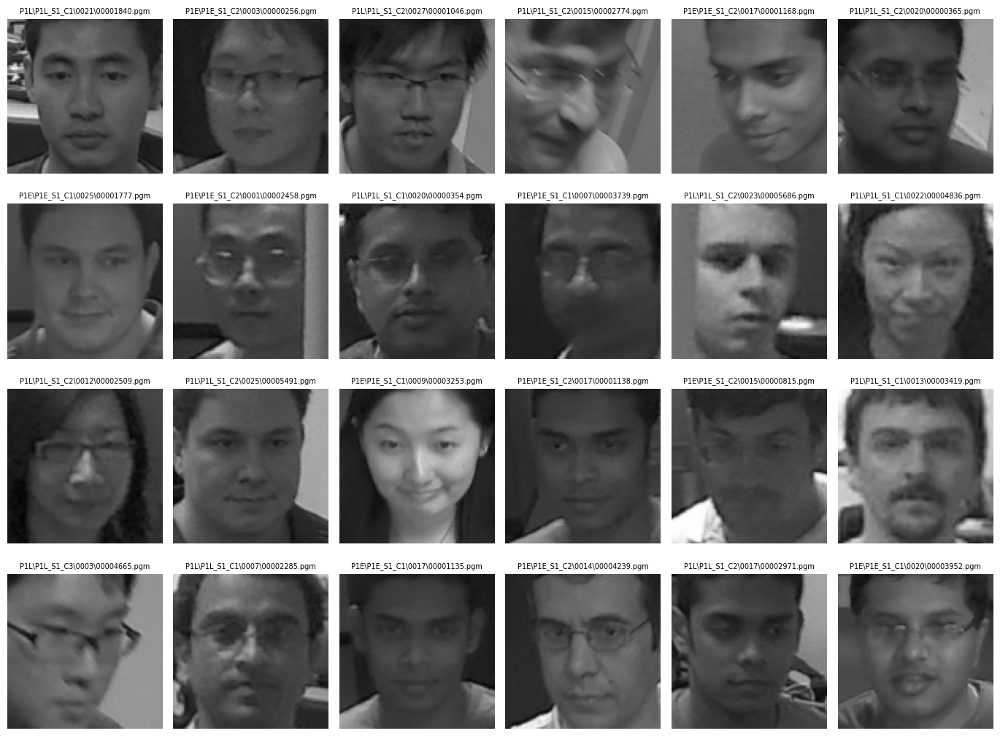

Displayed 24 sample images from 6,417 available images.
Portal 1 priority: yes


In [9]:
# Show sample ChokePoint images in a grid.
# This cell prioritizes Portal 1 images because P1 is the indoor case study focus.

from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
from PIL import Image

IMAGE_ROOT = Path("chokepoint_data/extracted")
MAX_IMAGES_TO_SHOW = 24
RANDOM_SEED = 391
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".ppm", ".pgm"}

all_images = sorted(
    path for path in IMAGE_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

portal1_images = [
    path for path in all_images
    if any(part.startswith(("P1E_S1", "P1L_S1")) for part in path.parts)
]

images_to_sample = portal1_images or all_images
if not images_to_sample:
    raise FileNotFoundError(
        f"No image files found under {IMAGE_ROOT.resolve()}. "
        "Download and extract P1E/P1L or the full dataset first."
    )

random.seed(RANDOM_SEED)
sample_size = min(MAX_IMAGES_TO_SHOW, len(images_to_sample))
sample_paths = random.sample(images_to_sample, sample_size)

cols = min(6, sample_size)
rows = math.ceil(sample_size / cols)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.3, rows * 2.6))
axes = list(getattr(axes, "flat", [axes]))

for ax in axes:
    ax.axis("off")

for ax, image_path in zip(axes, sample_paths):
    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))
    title = str(image_path.relative_to(IMAGE_ROOT))
    if len(title) > 44:
        title = "..." + title[-41:]
    ax.set_title(title, fontsize=7)

plt.tight_layout()
plt.show()

print(f"Displayed {sample_size} sample images from {len(images_to_sample):,} available images.")
print("Portal 1 priority:", "yes" if portal1_images else "no Portal 1 images found, used all images")


### Gallery: View all downloaded ChokePoint images (PGM support)

This cell renders thumbnails for all images under chokepoint_data/extracted. PGM files are converted to PNG data-URIs so they open in the browser. Click a thumbnail to open the full image in a new tab.


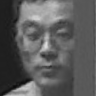
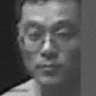
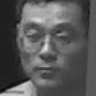
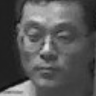
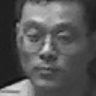
...
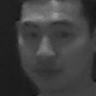
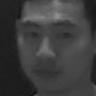
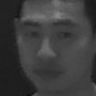
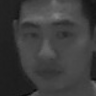
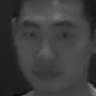

In [8]:
# Revised gallery: show full-frame thumbnails and overlay detected face bboxes (if available)
from pathlib import Path
from PIL import Image, ImageDraw
from io import BytesIO
import base64
from IPython.display import HTML, display

IMAGE_ROOT = Path('chokepoint_data/extracted')
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.ppm', '.pgm'}
MAX_DISPLAY = 1000  # limit number of thumbnails shown

all_images = sorted([p for p in IMAGE_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS])
if not all_images:
    print(f'No images found under {IMAGE_ROOT.resolve()}.')
else:
    # try to find faces DataFrame from Part III results (scored/audited/faces_df)
    faces_df = None
    if 'results' in globals() and isinstance(results, dict):
        for k in ('scored','audited','faces_df'):
            if k in results and results[k] is not None:
                faces_df = results[k]
                break

    # build lookup by absolute image path string
    faces_by_image = {}
    if faces_df is not None and not faces_df.empty:
        tmp = faces_df.copy()
        tmp['image_path'] = tmp['image_path'].astype(str)
        for img, g in tmp.groupby('image_path'):
            faces_by_image[img] = g.to_dict('records')

    cards = []
    for p in all_images[:MAX_DISPLAY]:
        try:
            with Image.open(p) as im:
                im_rgb = im.convert('RGB')
                # create a thumbnail for display
                thumb = im_rgb.copy()
                thumb.thumbnail((320,320))
                draw = ImageDraw.Draw(thumb)

                # find faces associated with this image (try exact path and filename heuristics)
                img_key = str(p.resolve())
                face_info = faces_by_image.get(img_key, [])
                if not face_info:
                    fname = p.name
                    for k,v in faces_by_image.items():
                        if fname == Path(k).name or fname.split('.')[0] in Path(k).stem:
                            face_info = v
                            break

                # draw bbox rectangles scaled to thumbnail
                if face_info:
                    ow, oh = im_rgb.size
                    tw, th = thumb.size
                    sx = tw/ow
                    sy = th/oh
                    for f in face_info:
                        try:
                            x0 = float(f.get('xmin',0))*sx
                            y0 = float(f.get('ymin',0))*sy
                            x1 = float(f.get('xmax',0))*sx
                            y1 = float(f.get('ymax',0))*sy
                            draw.rectangle([x0,y0,x1,y1], outline='red', width=2)
                        except Exception:
                            continue

                # encode thumbnail to data-uri
                buf = BytesIO()
                thumb.save(buf, format='PNG')
                thumb_b64 = base64.b64encode(buf.getvalue()).decode('ascii')
                thumb_uri = f'data:image/png;base64,{thumb_b64}'

                # prepare small face crops (up to 6) for quick inspection
                face_html = ''
                if face_info:
                    crops = []
                    for f in face_info[:6]:
                        try:
                            with Image.open(p) as im2:
                                im2 = im2.convert('RGB')
                                crop = im2.crop((f['xmin'], f['ymin'], f['xmax'], f['ymax']))
                                crop.thumbnail((96,96))
                                cb = BytesIO()
                                crop.save(cb, format='PNG')
                                crops.append('data:image/png;base64,'+base64.b64encode(cb.getvalue()).decode('ascii'))
                        except Exception:
                            continue
                    face_html = ''.join(f"<img src='{c}' style='width:64px;height:auto;margin:2px;border:1px solid #ccc;'>" for c in crops)

                # build card HTML (thumbnail links to original file via notebook file server)
                rel = p.resolve().as_posix()
                url = f'files/{rel}'
                info = f"<div style='font-size:11px;color:#333;margin-top:4px;'>{p.name}<br/>{im_rgb.size[0]}x{im_rgb.size[1]} px"
                if face_info:
                    info += f"<br/><b>{len(face_info)}</b> faces"
                info += "</div>"
                card = (
                    f"<div style='width:340px;padding:6px;margin:6px;border:1px solid #eee;background:#fff;'>"
                    f"<a href='{url}' target='_blank'><img src='{thumb_uri}' style='display:block;margin-bottom:4px;width:320px;'></a>"
                    f"{info}<div style='margin-top:6px;display:flex;flex-wrap:wrap'>{face_html}</div></div>"
                )
                cards.append(card)
        except Exception:
            continue

    gallery_html = '<div style="display:flex;flex-wrap:wrap;align-items:flex-start">' + ''.join(cards) + '</div>'
    header = f'<p>Displayed up to {MAX_DISPLAY} full-frame images from {len(all_images):,} available. Click image to open original file.</p>'
    display(HTML(header + gallery_html))

### Run full-dataset scan & show images that fit requirements

This cell will run the Part III advanced analyzer (if not already run), compute scale statistics (WIDER-like buckets and cumulative ratios), infer distances when possible, then display full-frame thumbnails for images that contain small faces (10–50 px min-side).

In [9]:
# filepath: d:\Admin\Download\DSP391m\DSP391M_Report2_template.ipynb
# Cell: scan dataset, compute stats, and show images with small faces (10-50 px)
from pathlib import Path
from PIL import Image, ImageDraw
from io import BytesIO
import base64
import numpy as np
import pandas as pd
from IPython.display import HTML, display

# Ensure Part III helpers are available
if 'run_part3_advanced' not in globals():
    print('run_part3_advanced not defined. Please run Part III cells first (the advanced EDA).')
else:
    # Run or reuse results
    if 'results' not in globals() or not isinstance(results, dict):
        print('Running Part III advanced analysis to build faces metadata (this may take a while)...')
        results = run_part3_advanced(images_df if 'images_df' in globals() else None, groundtruth_df if 'groundtruth_df' in globals() else None)
    # pick faces_df / scored if present
    faces_df = None
    if isinstance(results, dict):
        for k in ('scored','audited','faces_df'):
            if k in results and results[k] is not None:
                faces_df = results[k]
                break

    if faces_df is None or faces_df.empty:
        print('No faces found from annotations. Ensure ground-truth annotations are loaded or provide annotation files.')
    else:
        # Basic scale stats (cumulative ratios)
        s = faces_df['size_px'].dropna()
        print('\nScale summary:')
        print('Total annotated faces:', len(s))
        for th in (16, 32, 50, 100):
            print(f' Fraction <= {th}px: {(s<=th).mean():.3%} ({(s<=th).sum()})')

        # WIDER-like buckets summary
        buckets = { 'Small(10-50)': ((s>=10)&(s<50)).sum(),
                    'Medium(50-300)': ((s>=50)&(s<300)).sum(),
                    'Large(>=300)': (s>=300).sum() }
        print('\nWIDER-like buckets:')
        for k,v in buckets.items():
            print(f'  {k}: {v} faces')

        # CCTV distance median if inferable
        if 'infer_distance_from_path' in globals():
            faces_df = faces_df.copy()
            faces_df['image_path'] = faces_df['image_path'].astype(str)
            faces_df['distance_m'] = faces_df['image_path'].apply(infer_distance_from_path)
            dist_summary = faces_df.dropna(subset=['distance_m']).groupby('distance_m')['size_px'].median()
            if not dist_summary.empty:
                print('\nMedian face min-side by inferred distance (px):')
                print(dist_summary)
            else:
                print('\nNo distance metadata inferred from paths.')

        # Select faces matching requirements: small faces (10-50 px min-side)
        sel_faces = faces_df[(faces_df['size_px']>=10) & (faces_df['size_px']<50)].copy()
        print(f"\nSelected small faces (10-50 px): {len(sel_faces)}")
        if sel_faces.empty:
            print('No small faces found (10-50 px) in annotations.')
        else:
            # group by image and display gallery of full frames with overlaid bboxes and face crops
            faces_by_image = sel_faces.groupby(sel_faces['image_path'].astype(str))
            IMAGE_ROOT = Path('chokepoint_data/extracted')
            MAX_IMAGES = 60
            cards = []
            count = 0
            for img_path, group in faces_by_image:
                if count >= MAX_IMAGES:
                    break
                p = Path(img_path)
                if not p.exists():
                    # try resolve relative to working dirs
                    alt = IMAGE_ROOT.joinpath(Path(img_path).name)
                    if alt.exists():
                        p = alt
                    else:
                        continue
                try:
                    with Image.open(p) as im:
                        im_rgb = im.convert('RGB')
                        thumb = im_rgb.copy()
                        thumb.thumbnail((420,320))
                        draw = ImageDraw.Draw(thumb)
                        ow, oh = im_rgb.size
                        tw, th = thumb.size
                        sx = tw/ow
                        sy = th/oh
                        face_html = ''
                        crops = []
                        for _, f in group.iterrows():
                            try:
                                x0,y0,x1,y1 = float(f['xmin']), float(f['ymin']), float(f['xmax']), float(f['ymax'])
                            except Exception:
                                continue
                            # draw scaled rectangle on thumbnail
                            draw.rectangle([x0*sx, y0*sy, x1*sx, y1*sy], outline='red', width=2)
                            # create crop for quick view
                            try:
                                crop = im_rgb.crop((x0, y0, x1, y1))
                                crop.thumbnail((96,96))
                                cb = BytesIO()
                                crop.save(cb, format='PNG')
                                crops.append('data:image/png;base64,'+base64.b64encode(cb.getvalue()).decode('ascii'))
                            except Exception:
                                pass
                        if crops:
                            face_html = ''.join(f"<img src='{c}' style='width:64px;height:auto;margin:2px;border:1px solid #ccc;'>" for c in crops[:6])
                        buf = BytesIO()
                        thumb.save(buf, format='PNG')
                        thumb_b64 = base64.b64encode(buf.getvalue()).decode('ascii')
                        thumb_uri = 'data:image/png;base64,'+thumb_b64
                        url = f"files/{p.resolve().as_posix()}"
                        info = f"<div style='font-size:11px;color:#333;margin-top:4px;'>{p.name}<br/>{im_rgb.size[0]}x{im_rgb.size[1]} px<br/><b>{len(group)}</b> small face(s)</div>"
                        card = (
                            f"<div style='width:460px;padding:6px;margin:6px;border:1px solid #eee;background:#fff;'>"
                            f"<a href='{url}' target='_blank'><img src='{thumb_uri}' style='display:block;margin-bottom:4px;width:420px;'></a>"
                            f"{info}<div style='margin-top:6px;display:flex;flex-wrap:wrap'>{face_html}</div></div>"
                        )
                        cards.append(card)
                        count += 1
                except Exception as e:
                    # skip unreadable images
                    continue

            if cards:
                gallery_html = '<div style="display:flex;flex-wrap:wrap;align-items:flex-start">' + ''.join(cards) + '</div>'
                header = f"<p>Showing up to {len(cards)} images that contain small faces (10–50 px min-side). Click a thumbnail to open the original file.</p>"
                display(HTML(header + gallery_html))
            else:
                print('No gallery cards produced (images not found or unreadable).')

No faces found from annotations. Ensure ground-truth annotations are loaded or provide annotation files.


In [10]:
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import csv
import shutil
import sys

# Configuration
DATA_ROOT = Path("d:/Admin/Download/DSP391m/chokepoint_data/extracted")  # adjust if needed
OUTPUT_ROOT = Path("d:/Admin/Download/DSP391m/chokepoint_data_jpg")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".ppm", ".pgm", ".tiff", ".tif"}
QUALITY = 90
OVERWRITE = False  # set True to replace existing .jpg in OUTPUT_ROOT
MANIFEST_CSV = OUTPUT_ROOT / "conversion_manifest.csv"

def convert_image(src_path: Path, dest_path: Path):
    try:
        with Image.open(src_path) as im:
            im_rgb = im.convert("RGB")
            dest_path.parent.mkdir(parents=True, exist_ok=True)
            im_rgb.save(dest_path, format="JPEG", quality=QUALITY, optimize=True)
            return True, None
    except UnidentifiedImageError as e:
        return False, f"UnidentifiedImageError: {e}"
    except Exception as e:
        return False, str(e)

def main():
    if not DATA_ROOT.exists():
        print(f"DATA_ROOT not found: {DATA_ROOT}")
        return

    out_root = OUTPUT_ROOT
    out_root.mkdir(parents=True, exist_ok=True)

    # gather input images
    imgs = [p for p in DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
    print(f"Found {len(imgs)} image files under {DATA_ROOT}")

    manifest_rows = []
    failures = 0

    for src in imgs:
        rel = src.relative_to(DATA_ROOT)
        dest = out_root.joinpath(rel).with_suffix(".jpg")
        status = "skipped"
        err = ""

        if dest.exists() and not OVERWRITE:
            status = "exists"
        else:
            ok, err = convert_image(src, dest)
            if ok:
                status = "converted"
            else:
                status = "failed"
                failures += 1

        # collect basic metadata if conversion succeeded
        width = height = size_bytes = ""
        try:
            if dest.exists():
                with Image.open(dest) as im:
                    width, height = im.size
                size_bytes = dest.stat().st_size
        except Exception:
            pass

        manifest_rows.append({
            "src": str(src),
            "dest": str(dest),
            "status": status,
            "error": err,
            "width": width,
            "height": height,
            "size_bytes": size_bytes
        })

    # write manifest
    with MANIFEST_CSV.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["src","dest","status","error","width","height","size_bytes"])
        writer.writeheader()
        writer.writerows(manifest_rows)

    converted = sum(1 for r in manifest_rows if r["status"]=="converted")
    skipped = sum(1 for r in manifest_rows if r["status"] in ("exists","skipped"))
    failed = sum(1 for r in manifest_rows if r["status"]=="failed")
    print(f"Converted: {converted}, Skipped/Exists: {skipped}, Failed: {failed}")
    print(f"Manifest written to: {MANIFEST_CSV}")

if __name__ == "__main__":
    main()


Found 63628 image files under d:\Admin\Download\DSP391m\chokepoint_data\extracted
Converted: 63628, Skipped/Exists: 0, Failed: 0
Manifest written to: d:\Admin\Download\DSP391m\chokepoint_data_jpg\conversion_manifest.csv
Converted: 63628, Skipped/Exists: 0, Failed: 0
Manifest written to: d:\Admin\Download\DSP391m\chokepoint_data_jpg\conversion_manifest.csv


In [1]:
# Recursively extract nested ChokePoint archives until no .tar or .tar.xz files remain.
# This only works inside chokepoint_data/extracted and does not touch the original downloads.

from pathlib import Path
import os
import tarfile

try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = None

EXTRACT_ROOT = Path("chokepoint_data/extracted")
ARCHIVE_SUFFIXES = (".tar.xz", ".tar")
DELETE_ARCHIVES_AFTER_EXTRACTION = True
MAX_PASSES = 50

def is_archive_file(path: Path) -> bool:
    name = path.name.lower()
    return any(name.endswith(suffix) for suffix in ARCHIVE_SUFFIXES)

def archive_output_dir(archive_path: Path) -> Path:
    name = archive_path.name
    for suffix in ARCHIVE_SUFFIXES:
        if name.lower().endswith(suffix):
            return archive_path.with_name(name[:-len(suffix)])
    return archive_path.with_suffix("")

def is_safe_member(base_dir: Path, member_name: str) -> bool:
    base_dir = base_dir.resolve()
    target_path = (base_dir / member_name).resolve()
    return str(target_path) == str(base_dir) or str(target_path).startswith(str(base_dir) + os.sep)

def list_archives(root: Path):
    return sorted(
        path for path in root.rglob("*")
        if path.is_file() and is_archive_file(path)
    )

def extract_one_archive(archive_path: Path):
    target_dir = archive_output_dir(archive_path)
    marker_path = target_dir / ".extract_complete"
    if marker_path.exists():
        return "already_extracted"

    target_dir.mkdir(parents=True, exist_ok=True)
    print(f"Extracting {archive_path.relative_to(EXTRACT_ROOT)} -> {target_dir.relative_to(EXTRACT_ROOT)}")
    with tarfile.open(archive_path, mode="r:*") as tar:
        members = tar.getmembers()
        for member in members:
            if not is_safe_member(target_dir, member.name):
                raise RuntimeError(f"Unsafe path in archive {archive_path}: {member.name}")
        iterator = members if tqdm is None else tqdm(members, desc=archive_path.name, unit="file")
        for member in iterator:
            tar.extract(member, path=target_dir)

    marker_path.write_text("ok\n", encoding="utf-8")
    if DELETE_ARCHIVES_AFTER_EXTRACTION and archive_path.exists():
        archive_path.unlink()
    return target_dir

def extract_all_nested_archives(root: Path = EXTRACT_ROOT):
    if not root.exists():
        raise FileNotFoundError(f"Extract root not found: {root}")

    total_extracted = 0
    for pass_index in range(1, MAX_PASSES + 1):
        archives = list_archives(root)
        if not archives:
            print(f"No more archives found after pass {pass_index - 1}.")
            break

        print(f"Pass {pass_index}: {len(archives)} archive files found.")
        extracted_this_pass = 0
        for archive_path in archives:
            result = extract_one_archive(archive_path)
            if result == "already_extracted":
                if DELETE_ARCHIVES_AFTER_EXTRACTION and archive_path.exists():
                    archive_path.unlink()
                continue
            extracted_this_pass += 1
            total_extracted += 1

        print(f"Pass {pass_index} complete: extracted {extracted_this_pass} archives.")

    remaining_archives = list_archives(root)
    print(f"Total archives extracted in this run: {total_extracted}")
    print(f"Remaining archive files under extracted: {len(remaining_archives)}")
    for path in remaining_archives[:25]:
        print(path)

# Safety switch: set this to YES when you are ready to fully unpack the nested archives.
RUN_RECURSIVE_EXTRACTION = "YES"

if RUN_RECURSIVE_EXTRACTION == "YES":
    extract_all_nested_archives()
else:
    print('Recursive extraction is prepared but not started. Set RUN_RECURSIVE_EXTRACTION = "YES" to run it.')


d:\Anaconda3\envs\cvlface\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Pass 1: 54 archive files found.
Extracting P1E_S1\P1E_S1_C1.tar.xz -> P1E_S1\P1E_S1_C1


P1E_S1_C1.tar.xz: 100%|██████████| 2296/2296 [00:07<00:00, 293.12file/s]


Extracting P1E_S1\P1E_S1_C2.tar.xz -> P1E_S1\P1E_S1_C2


P1E_S1_C2.tar.xz: 100%|██████████| 2296/2296 [00:08<00:00, 261.82file/s]


Extracting P1E_S1\P1E_S1_C3.tar.xz -> P1E_S1\P1E_S1_C3


... (100 outputs left out)

P2L_S5_C2.tar.xz: 100%|██████████| 758/758 [00:01<00:00, 415.36file/s]


Extracting P2L_S5\P2L_S5_C3.tar.xz -> P2L_S5\P2L_S5_C3


P2L_S5_C3.tar.xz: 100%|██████████| 758/758 [00:02<00:00, 264.48file/s]


Pass 1 complete: extracted 54 archives.
No more archives found after pass 1.
Total archives extracted in this run: 54
Remaining archive files under extracted: 0
